In [1]:
import pandas as pd
import numpy as np

In [2]:
data = 'housing_data_CDMX_v2.csv'

df = pd.read_csv('housing_data_CDMX_v2.csv')

# Initial Data Inspection

### Dimension of the dataset

In [3]:
df.shape

(18234, 13)

The dataset consists of 18,234 instances (rows) and 13 variables (columns)

### Preview the dataset


In [4]:
df.head(5)

,property_type,places,lat-lon,price,currency,price_aprox_local_currency,price_aprox_usd,surface_total_in_m2,surface_covered_in_m2,price_usd_per_m2,price_per_m2,lat,lon
0,apartment,MiguelHidalgo,"23.634501,-102.552788",5500000.0,MXN,5450245.50,289775.66,54.0,54.0,5366.215926,101851.85190,23.634501,-102.552788
1,house,Iztapalapa,"19.31033,-99.068557",1512000.0,MXN,1498321.97,79661.96,80.0,80.0,995.774500,18900.00000,19.310330,-99.068557
2,apartment,Tlalpan,"19.279771,-99.234597",926667.0,MXN,918284.00,48822.82,100.0,100.0,488.228200,9266.67000,19.279771,-99.234597
3,apartment,MiguelHidalgo,"23.634501,-102.552788",6410000.0,MXN,6352013.39,337720.36,135.0,135.0,2501.632296,47481.48148,23.634501,-102.552788
4,apartment,MiguelHidalgo,"19.432657,-99.177444",4416000.0,MXN,4376051.62,232663.51,87.0,87.0,2674.293218,50758.62069,19.432657,-99.177444


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 18234 entries, 0 to 18233
Data columns (total 13 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   property_type               18234 non-null  str    
 1   places                      18234 non-null  str    
 2   lat-lon                     18234 non-null  str    
 3   price                       18234 non-null  float64
 4   currency                    18234 non-null  str    
 5   price_aprox_local_currency  18234 non-null  float64
 6   price_aprox_usd             18234 non-null  float64
 7   surface_total_in_m2         18234 non-null  float64
 8   surface_covered_in_m2       18234 non-null  float64
 9   price_usd_per_m2            18234 non-null  float64
 10  price_per_m2                18234 non-null  float64
 11  lat                         18234 non-null  float64
 12  lon                         18234 non-null  float64
dtypes: float64(9), str(4)
memory usage: 2.6 MB

### with df.info(), we get a complete structural summary of the dataframe.

**Categorical and Location Variables (Text)**:

- property_type: Type of listed property (apartment, house, PH (Horizontal Property , commercial space).
- places: Administrative location or geographic hierarchy of the property (province/state, city, or neighborhood).
- lat-lon: Geographic coordinates combined into a single text string.
- currency: Original currency in which the property price was listed (MXN, USD).

**Numerical Price Variables**:

- price: Original listed sale price for the property.
- price_aprox_local_currency: Approximate price converted to the corresponding local currency.
- price_aprox_usd: Approximate price standardized in U.S. dollars (USD).
- price_usd_per_m2: Price per square meter calculated in U.S. dollars.
- price_per_m2: Price per square meter in the original listing currency.

**Numerical Area and Coordinate Variables**:

- surface_total_in_m2: Total area of the property measured in square meters (square meter 𝑚2).
- surface_covered_in_m2: Covered or built-up area measured in square meters (square meter 𝑚2).
- lat: Geographic latitude in decimal format.
- lon: Geographic longitude in decimal format.


### Missing Values

In [6]:
df.isnull().sum()

property_type                 0
places                        0
lat-lon                       0
price                         0
currency                      0
price_aprox_local_currency    0
price_aprox_usd               0
surface_total_in_m2           0
surface_covered_in_m2         0
price_usd_per_m2              0
price_per_m2                  0
lat                           0
lon                           0
dtype: int64

The above command shows that there are no missing values in the dataset.

# Initial Exploratory Data Analysis

- We will verify if there are properties listed more than once using df.duplicated().sum().
  
- The lat-lon column contains the exact same information as lat and lon separately, so we will drop it to simplify the analysis.

- We will check with df.describe() that there are no areas with 0 square meters, unrealistic prices, or cases where surface_covered_in_m2 is greater than surface_total_in_m2.

### Property Type Distribution before Cleaning

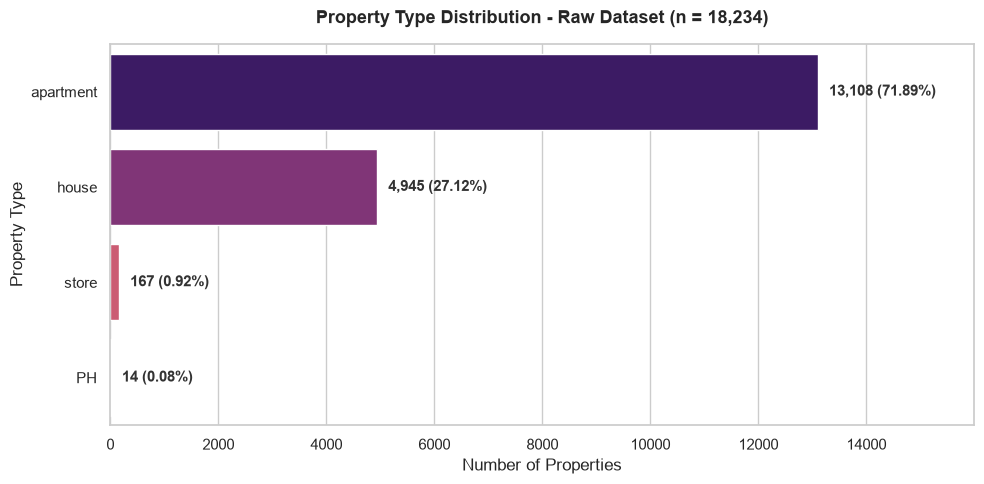

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate raw counts and percentages (before cleaning)
raw_counts = df['property_type'].value_counts()
total_raw = len(df)

plt.figure(figsize=(10, 5))
sns.set_theme(style="whitegrid")

# Horizontal bar plot
ax = sns.barplot(x=raw_counts.values, y=raw_counts.index, hue=raw_counts.index, palette='magma', legend=False)

# Add exact count and percentage labels to each bar
for index, value in enumerate(raw_counts.values):
    percentage = (value / total_raw) * 100
    ax.text(value + 200, index, f'{value:,} ({percentage:.2f}%)', va='center', fontsize=11, fontweight='bold', color='#333333')

# Titles and axes
plt.title(f'Property Type Distribution - Raw Dataset (n = {total_raw:,})', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Number of Properties')
plt.ylabel('Property Type')
plt.xlim(0, max(raw_counts.values) * 1.22)  # Extra space on the right for labels

plt.tight_layout()
plt.show()


# Data Cleaning

### Identify Duplicated Rows

In [8]:
df.duplicated().sum()

np.int64(2953)

This code checks each row in the DataFrame to identify duplicate rows. 
The result shows a single integer representing 2,953 of duplicate rows in the DataFrame

In [9]:
df = df.drop_duplicates().reset_index(drop=True)

After removing duplicates, this code resets the DataFrame's index to a default integer index 

During the first data analysis, although no null values were found, **2,953 duplicate records were detected**. 

These were removed to ensure the uniqueness of each property, resulting in a clean sample of **15,281 properties**.

### Identifying Duplicate Columns by Location and Surface 

In [10]:
key_columns = ['property_type', 'lat', 'lon', 'surface_total_in_m2', 'surface_covered_in_m2']
partial_duplicates = df.duplicated(subset=key_columns).sum()
print(f"Partial duplicates found: {partial_duplicates}")

Partial duplicates found: 2032


### Identifying duplicated Columns by Property Type

In [11]:
partial_dup_df = df[df.duplicated(subset=key_columns, keep=False)]
print("Partial duplicates found by property type:")
partial_dup_df['property_type'].value_counts()

Partial duplicates found by property type:


property_type
apartment    2927
house         488
store          15
Name: count, dtype: int64

### Identifying Duplicated Properties if Location, Surface and Price are identical

In [12]:
# Separate apartments from other property types
apartments = df[df['property_type'] == 'apartment']
others = df[df['property_type'] != 'apartment'] 

This separation allows for different deduplication strategies to be applied to apartments versus other property types in the subsequent code.

`apartments =` - The filtered DataFrame containing only apartment properties is assigned to a new variable called `apartments`.

`others =` - The filtered DataFrame containing all non-apartment properties is assigned to a new variable called `others`.

In [13]:
# Drop duplicated Apartments only if location, surface AND price are identical
# This includes property type, location (lat/lon), surface areas, and price.
apt_columns = ['property_type', 'lat', 'lon', 'surface_total_in_m2', 'surface_covered_in_m2', 'price_aprox_usd']
apartments_clean = apartments.drop_duplicates(subset=apt_columns, keep='first')

`subset=apt_columns` - Only considers the columns listed in 'apt_columns' when checking for duplicates, rather than comparing all columns.

`keep='first'` - When duplicates are found, this parameter keeps the first occurrence and removes subsequent duplicates.

`apartments_clean =` Assigns the resulting DataFrame (with duplicates removed) to a new variable called `apartments_clean`.

In [14]:
# Drop duplicated Houses, Storers or Horizontal Properties if location and surface are identical
other_columns = ['property_type', 'lat', 'lon', 'surface_total_in_m2', 'surface_covered_in_m2']
others_clean = others.drop_duplicates(subset=other_columns, keep='first')

`other_columns` creates a list containing five column names that will be used to identify duplicate entries for non-apartment properties.

`others.drop_duplicates(subset=other_columns, keep='first')` removes duplicate rows from the `others` DataFrame where all five specified columns have identical values.

`others_clean =` Assigns the resulting DataFrame (with duplicates removed) to a new variable called `others_clean`.


In [15]:
# Combine into the clean dataframe
df = pd.concat([apartments_clean, others_clean], ignore_index=True) # This function combine `apartments_clean` and `others_clean`

#  Calculate and display how many apartment records were removed by subtracting the cleaned count from the original count.
print(f"Apartments removed: {len(apartments) - len(apartments_clean)}")

# To show how many non-apartment property records were removed during the cleaning process.
print(f"Other properties removed: {len(others) - len(others_clean)}")

# To display the final dimensions (rows, columns) of the combined cleaned DataFrame.
print(f"Dataset shape after selective deduplication: {df.shape}")


Apartments removed: 23
Other properties removed: 272
Dataset shape after selective deduplication: (14986, 13)


To avoid removing distinct residential units located within the same building, a two-tier deduplication strategy was applied. For **apartments**, records were dropped only when sharing identical coordinates, surface areas, and standardized USD price (23 duplicate postings removed). For **houses, stores, and PH units**, matching coordinates and dimensions alone were used to filter out multi-agency reposts (272 duplicates removed), consolidating the dataset to **14,986 unique properties**.
